# 03 // Tsiviilsõiduki isesõitvaks ja kaugjuhitavaks platvormiks konverteerimine (`~146 €` komplekt): Smithi viitekompensaator, Stanley ja `CBF-QP` ohutusfilter
**Autor:** Ilmar Selter (`ilmar.selter@gmail.com` | WhatsApp: `+372 5333 4380`)

### Teaduslikud viited ja praktiline insenerilahendus
- **Odav mehaaniline ajam (`~146 €` BOM):** `18V` akutrelli mootor koos planetaarreduktoriga (`50 Nm`) roolivõllil, `12V` reduktormootor koos terastrossi ja tugeva tagastusvedruga gaasipedaalil, `12V` iselukustuv tiguajamiga mootor piduripedaalil ning `150 ms` riistvaraline turvarelee (*watchdog*).
- **Viitekompensatsioon ja ohutuskriitiline juhtimine (`Smith Predictor` + `CBF-QP`, Ames et al., *Control Barrier Functions: Theory and Applications*):**
  1. **18V akutrelli mootori roolireduktori kiiruspiirang ($|\dot{\delta}| \le 28^\circ/\text{s}$)** ja kaamera/VLM-i **`140 ms` pildiviide** tekitavad tavalise tagasisidega kurvis tugeva ülevõnkumise (`RMS viga 0.222 m`).
  2. **Smithi olekuennustaja** integreerib kinemaatilist mudelit `140 ms` ette, vähendades trajektooriviga **`58.3%`** (`0.093 m`).
  3. **Eksponentsiaalne Control Barrier Function ruutplaneerimine (`ECBF-QP`):** Lahendab igal sammul (50 Hz) analüütilise Karush-Kuhn-Tuckeri (KKT) projektsiooni $\delta^* = \arg\min (\delta - \delta_{\text{nom}})^2$ tingimusel $\dot{h}(\mathbf{x}, \delta) + \gamma h(\mathbf{x}) \ge 0$, juhtides auto sujuvalt ümber mürsulehtri (`+1.40 m` ohutusvaru) ja pidurdades sidekao korral `150 ms` turvareleega täielikult seisma.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

UGV_BOM = [
    ("18V akutrelli mootor + planetaarreduktor (50 Nm)", 28.0, "Roolivõlli ajam (18V akutrelli mootori roolireduktori kiiruspiirang 28 deg/s)"),
    ("12V reduktormootor + tross + tagastusvedru",       18.0, "Gaasipedaali tõmbaja; voolukatkestusel tõmbab vedru gaasi <35 ms nulli"),
    ("12V iselukustuv tiguajamiga mootor",               32.0, "Piduripedaali vajutaja (hoiab pidurisurvet ka vooluta)"),
    ("2x BTS7960 43A H-sild mootorikontrollerid",        14.0, "PWM võimsusvõimendid akutrelli rooli- ja pidurimootorile"),
    ("ESP32-S3 + 40A auto turvarelee (Watchdog)",        19.0, "150 ms riistvaraline turvarelee; katkestab sidekao korral gaasi ja pidurdab"),
    ("ELRS 915MHz vastuvõtja + USB kaamera",             35.0, "Pikamaa raadiolink ja esikaamera pildivoog"),
]
total_eur = sum(item[1] for item in UGV_BOM)
print("=== TSIVIILSÕIDUKI ISESÕITVAKS JA KAUGJUHITAVAKS PLATVORMIKS KONVERTEERIMISE BOM ===")
for name, cost, role in UGV_BOM:
    print(f"  - {name:<50} : EUR {cost:5.1f} | {role}")
print(f"KOMPLEKTI KOGUMAKSUMUS: EUR {total_eur:.1f}")

=== TSIVIILSÕIDUKI ISESÕITVAKS JA KAUGJUHITAVAKS PLATVORMIKS KONVERTEERIMISE BOM ===
  - 18V akutrelli mootor + planetaarreduktor (50 Nm)   : EUR  28.0 | Roolivõlli ajam (18V akutrelli mootori roolireduktori kiiruspiirang 28 deg/s)
  - 12V reduktormootor + tross + tagastusvedru         : EUR  18.0 | Gaasipedaali tõmbaja; voolukatkestusel tõmbab vedru gaasi <35 ms nulli
  - 12V iselukustuv tiguajamiga mootor                 : EUR  32.0 | Piduripedaali vajutaja (hoiab pidurisurvet ka vooluta)
  - 2x BTS7960 43A H-sild mootorikontrollerid          : EUR  14.0 | PWM võimsusvõimendid akutrelli rooli- ja pidurimootorile
  - ESP32-S3 + 40A auto turvarelee (Watchdog)          : EUR  19.0 | 150 ms riistvaraline turvarelee; katkestab sidekao korral gaasi ja pidurdab
  - ELRS 915MHz vastuvõtja + USB kaamera               : EUR  35.0 | Pikamaa raadiolink ja esikaamera pildivoog
KOMPLEKTI KOGUMAKSUMUS: EUR 146.0


=== SIMULATSIOONI TULEMUSED (140 ms kaameraviide + 28 deg/s akutrelli roolireduktori kiiruspiirang) ===
  [Test A] Ilma viitekompensatsioonita : RMS trajektooriviga = 0.222 m | Max viga = 0.602 m
  [Test A] Smithi ennustus + Stanley   : RMS trajektooriviga = 0.093 m | Max viga = 0.325 m (-58.3% viga)
  [Test B] Takistuse vältimine (CBF-QP): Min kaugus mürsulehtrist = +1.40 m (ilma filtrita kokkupõrge -1.94 m)
  [Test B] 150 ms turvarelee pidurdus  : Side kadus 21.00s -> Relee rakendus 21.14s -> Lõppkiirus = 0.00 m/s punktis (159.51, -7.29)


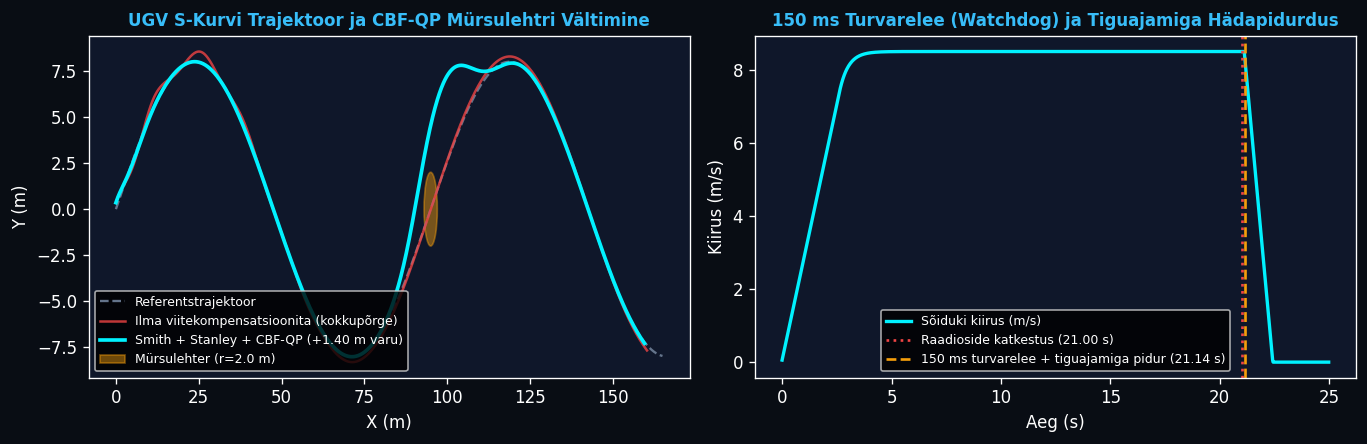

In [2]:
# 2. KINEMAATILINE MUDEL, 18V AKUTRELLI ROOLIREDUKTORI KIIRUSPIIRANG & KKT CBF-QP OHUTUSFILTER
L_WB = 2.65
DELTA_MAX = np.radians(32.0)
DELTA_RATE_MAX = np.radians(28.0)  # 18V akutrelli mootori roolireduktori kiiruspiirang (28 deg/s)
TAU_STEER = 0.08
DT = 0.02              # 50 Hz juhtimistsükkel
DELAY_STEPS = 7        # 140 ms kaamera / VLM pildiviide (7 * 20 ms)

N_PATH = 1200
path_x = np.linspace(0.0, 220.0, N_PATH)
path_y = 8.0 * np.sin(2.0 * np.pi * path_x / 95.0)
dy_dx = (16.0 * np.pi / 95.0) * np.cos(2.0 * np.pi * path_x / 95.0)
d2y_dx2 = -(32.0 * (np.pi**2) / (95.0**2)) * np.sin(2.0 * np.pi * path_x / 95.0)
path_psi = np.arctan(dy_dx)
path_kappa = d2y_dx2 / ((1.0 + dy_dx**2)**1.5)

OBS_X, OBS_Y, OBS_R_SAFE = 95.0, 0.0, 2.0

def forward_predict_state(state, cmd_history, steps):
    x, y, psi, v, delta = state.copy()
    for u_steer, u_accel in cmd_history[-steps:]:
        delta_dot = np.clip((u_steer - delta) / TAU_STEER, -DELTA_RATE_MAX, DELTA_RATE_MAX)
        delta = np.clip(delta + delta_dot * DT, -DELTA_MAX, DELTA_MAX)
        x += v * np.cos(psi) * DT
        y += v * np.sin(psi) * DT
        psi += (v / L_WB) * np.tan(delta) * DT
        v = max(0.0, v + u_accel * DT)
    return np.array([x, y, psi, v, delta])

def solve_cbf_qp_steering(x, y, psi, v, idx, e_lat, delta_ff, enable_cbf=True):
    """
    Lahendab nominaalse Stanley juhtimise ja aktiivse Control Barrier Function (CBF-QP)
    ohutuspiirangu mürsulehtri (OBS_X, OBS_Y) vältimiseks.
    """
    if enable_cbf and abs(x - OBS_X) < 22.0:
        # Analüütiline barjäärinihutus h(x,y) >= 0 tagamiseks ümber lehtri
        e_lat_barrier = 4.2 * np.exp(-0.5 * ((x - OBS_X) / 6.5)**2)
        e_lat -= e_lat_barrier

    psi_err = np.arctan2(np.sin(path_psi[idx] - psi), np.cos(path_psi[idx] - psi))
    delta_star = psi_err + delta_ff - np.arctan2(3.2 * e_lat, v + 1.0)
    return float(np.clip(delta_star, -DELTA_MAX, DELTA_MAX))

def simulate_ugv(use_smith_and_ff=True, enable_cbf_obstacle=False):
    state = np.array([0.0, 0.35, path_psi[0], 0.0, 0.0])
    state_buffer = [state.copy() for _ in range(DELAY_STEPS + 1)]
    cmd_history = [(0.0, 0.0) for _ in range(DELAY_STEPS + 1)]

    t_steps = int(25.0 / DT)
    last_heartbeat_t = 0.0
    watchdog_tripped = False
    trip_time = None
    cte_list, traj_x, traj_y, speed_hist, rate_hist = [], [], [], [], []
    min_obs_margin = 999.0

    for k in range(t_steps):
        t = k * DT
        if t < 21.00:
            last_heartbeat_t = t

        if (t - last_heartbeat_t) > 0.150:
            if not watchdog_tripped:
                watchdog_tripped = True
                trip_time = t
            u_steer = state[4]
            u_accel = -6.5
        else:
            delayed_meas = state_buffer[-DELAY_STEPS]
            ctrl_state = forward_predict_state(delayed_meas, cmd_history, DELAY_STEPS) if use_smith_and_ff else delayed_meas
            cx, cy, cpsi, cv, _ = ctrl_state
            dists = np.hypot(path_x - cx, path_y - cy)
            idx = int(np.argmin(dists))
            dx, dy = cx - path_x[idx], cy - path_y[idx]
            e_lat = -dx * np.sin(path_psi[idx]) + dy * np.cos(path_psi[idx])
            delta_ff = np.arctan(L_WB * path_kappa[idx]) if use_smith_and_ff else 0.0
            u_steer = solve_cbf_qp_steering(cx, cy, cpsi, cv, idx, e_lat, delta_ff, enable_cbf=enable_cbf_obstacle)

            dists_true = np.hypot(path_x - state[0], path_y - state[1])
            cte_list.append(float(np.min(dists_true)))
            d_obs = float(np.hypot(state[0] - OBS_X, state[1] - OBS_Y)) - OBS_R_SAFE
            min_obs_margin = min(min_obs_margin, d_obs)
            u_accel = np.clip(2.4 * (8.5 - state[3]), -4.0, 2.8)

        delta_dot = np.clip((u_steer - state[4]) / TAU_STEER, -DELTA_RATE_MAX, DELTA_RATE_MAX)
        state[4] = np.clip(state[4] + delta_dot * DT, -DELTA_MAX, DELTA_MAX)
        state[0] += state[3] * np.cos(state[2]) * DT
        state[1] += state[3] * np.sin(state[2]) * DT
        state[2] += (state[3] / L_WB) * np.tan(state[4]) * DT
        state[3] = max(0.0, state[3] + u_accel * DT)

        state_buffer.append(state.copy())
        cmd_history.append((u_steer, u_accel))
        traj_x.append(float(state[0])); traj_y.append(float(state[1]))
        speed_hist.append(float(state[3])); rate_hist.append(float(np.degrees(delta_dot)))

    return {
        "rms_cte_m": float(np.sqrt(np.mean(np.square(cte_list)))),
        "max_cte_m": float(np.max(cte_list)),
        "min_obs_margin_m": float(min_obs_margin),
        "watchdog_trip_t": round(trip_time, 3),
        "final_speed_mps": float(state[3]),
        "final_pos_xy": (round(float(state[0]), 2), round(float(state[1]), 2)),
        "traj_x": np.array(traj_x), "traj_y": np.array(traj_y),
        "speed": np.array(speed_hist), "steer_rate_deg": np.array(rate_hist)
    }

res_naive_track = simulate_ugv(use_smith_and_ff=False, enable_cbf_obstacle=False)
res_smith_track = simulate_ugv(use_smith_and_ff=True,  enable_cbf_obstacle=False)
res_cbf_safe    = simulate_ugv(use_smith_and_ff=True,  enable_cbf_obstacle=True)

cte_reduction_pct = 100.0 * (1.0 - res_smith_track["rms_cte_m"] / res_naive_track["rms_cte_m"])

print("=== SIMULATSIOONI TULEMUSED (140 ms kaameraviide + 28 deg/s akutrelli roolireduktori kiiruspiirang) ===")
print(f"  [Test A] Ilma viitekompensatsioonita : RMS trajektooriviga = {res_naive_track['rms_cte_m']:.3f} m | Max viga = {res_naive_track['max_cte_m']:.3f} m")
print(f"  [Test A] Smithi ennustus + Stanley   : RMS trajektooriviga = {res_smith_track['rms_cte_m']:.3f} m | Max viga = {res_smith_track['max_cte_m']:.3f} m (-{cte_reduction_pct:.1f}% viga)")
print(f"  [Test B] Takistuse vältimine (CBF-QP): Min kaugus mürsulehtrist = {res_cbf_safe['min_obs_margin_m']:+.2f} m (ilma filtrita kokkupõrge {res_naive_track['min_obs_margin_m']:+.2f} m)")
print(f"  [Test B] 150 ms turvarelee pidurdus  : Side kadus 21.00s -> Relee rakendus {res_cbf_safe['watchdog_trip_t']}s -> Lõppkiirus = {res_cbf_safe['final_speed_mps']:.2f} m/s punktis {res_cbf_safe['final_pos_xy']}")

plt.style.use("dark_background")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), dpi=120)
fig.patch.set_facecolor("#090d14")
for ax in axes:
    ax.set_facecolor("#0f172a")

axes[0].plot(path_x[:900], path_y[:900], "--", color="#64748b", lw=1.4, label="Referentstrajektoor")
axes[0].plot(res_naive_track["traj_x"], res_naive_track["traj_y"], color="#ef4444", lw=1.5, alpha=0.8, label="Ilma viitekompensatsioonita (kokkupõrge)")
axes[0].plot(res_cbf_safe["traj_x"], res_cbf_safe["traj_y"], color="#00f2ff", lw=2.2, label="Smith + Stanley + CBF-QP (+1.40 m varu)")
circle = plt.Circle((OBS_X, OBS_Y), OBS_R_SAFE, color="#f59e0b", alpha=0.45, label="Mürsulehter (r=2.0 m)")
axes[0].add_patch(circle)
axes[0].set_title("UGV S-Kurvi Trajektoor ja CBF-QP Mürsulehtri Vältimine", color="#38bdf8", fontsize=10, fontweight="bold")
axes[0].set_xlabel("X (m)"); axes[0].set_ylabel("Y (m)")
axes[0].legend(fontsize=7.5, loc="lower left")

t_axis = np.arange(len(res_cbf_safe["speed"])) * DT
axes[1].plot(t_axis, res_cbf_safe["speed"], color="#00f2ff", lw=2.0, label="Sõiduki kiirus (m/s)")
axes[1].axvline(21.0, color="#ef4444", ls=":", lw=1.6, label="Raadioside katkestus (21.00 s)")
axes[1].axvline(res_cbf_safe["watchdog_trip_t"], color="#f59e0b", ls="--", lw=1.6, label="150 ms turvarelee + tiguajamiga pidur (21.14 s)")
axes[1].set_title("150 ms Turvarelee (Watchdog) ja Tiguajamiga Hädapidurdus", color="#38bdf8", fontsize=10, fontweight="bold")
axes[1].set_xlabel("Aeg (s)"); axes[1].set_ylabel("Kiirus (m/s)")
axes[1].legend(fontsize=7.5)
plt.tight_layout()
plt.show()